# Phase 6 - Model Preprocessing & Logistic Regression Training (Real Execution)

Source: `data/processed/model_ready_data.csv` (read-only; raw/cleaned files untouched).

All logic lives in `src/preprocessing.py`, `src/evaluate.py`, `src/train.py` - the same
functions used by the standalone training script, so notebook and script produce identical,
deterministic artifacts (seeded splits, seeded CV).

Discipline: preprocessing is fitted **only on training data** (inside pipelines); the test set
is touched once per candidate model; class weight and feature set are chosen **only** on
training/CV evidence; all test metrics come from one prediction array + one probability array
and are mathematically verified against the confusion matrix.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.evaluate as ev
import src.preprocessing as prep
import src.train as train

pd.set_option("display.width", 200)
results = {"lines": []}
print("Model-ready:", prep.MODEL_READY_PATH)

Model-ready: data\processed\model_ready_data.csv


## 1. Load model-ready data

In [2]:
clean_sha_before = prep.clean_sha256()
raw_sha = prep.raw_sha256()
print("Cleaned SHA-256:", clean_sha_before)
print("Raw SHA-256    :", raw_sha)

df = prep.load_model_ready()  # runs full verification (7043 rows, unique IDs, 0/1 target, no missing, 24 predictors)
results["df_shape"] = df.shape
print(f"Verification passed: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Cleaned SHA-256: 38e6f2dd278033a4617f880e8f11304c5fc6dce2c05ecef3f2a8bf48eeaa8996
Raw SHA-256    : 16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91
Verification passed: 7043 rows x 26 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,TenureGroup,PhoneService,MultipleLines,InternetService,...,ServiceCount,HasSecuritySupport,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,MonthlyChargeBand,TotalCharges,AvgMonthlyCharge,Churn
0,7590-VHVEG,Female,0,Yes,No,1,≤6 months,No,No phone service,DSL,...,1,0,Month-to-month,Yes,Electronic check,29.85,Low,29.85,29.850000,0
1,5575-GNVDE,Male,0,No,No,34,25+ months,Yes,No,DSL,...,2,1,One year,No,Mailed check,56.95,Medium-Low,1889.50,55.573529,0
2,3668-QPYBK,Male,0,No,No,2,≤6 months,Yes,No,DSL,...,2,1,Month-to-month,Yes,Mailed check,53.85,Medium-Low,108.15,54.075000,1
3,7795-CFOCW,Male,0,No,No,45,25+ months,No,No phone service,DSL,...,3,1,One year,No,Bank transfer (automatic),42.30,Medium-Low,1840.75,40.905556,0
4,9237-HQITU,Female,0,No,No,2,≤6 months,Yes,No,Fiber optic,...,0,0,Month-to-month,Yes,Electronic check,70.70,Medium-High,151.65,75.825000,1


## 2. Define target / features (explicit feature groups)

`customerID` is stored **separately** as an identifier and never enters the feature matrix;
`Churn` is the target.

In [3]:
X, y, ids = prep.make_xy(df)
results["feature_groups"] = {"numeric": prep.NUMERIC_FEATURES, "categorical": prep.CATEGORICAL_FEATURES}
print(f"numeric    ({len(prep.NUMERIC_FEATURES)}): {prep.NUMERIC_FEATURES}")
print(f"categorical({len(prep.CATEGORICAL_FEATURES)}): {prep.CATEGORICAL_FEATURES}")
print(f"identifier : customerID (kept out of X) | target: Churn")
print(f"X: {X.shape}, y: {y.shape}, ids: {ids.shape}, churn rate: {y.mean():.4f}")
assert prep.ID_COL not in X.columns and prep.TARGET not in X.columns
print("PASS  customerID and Churn excluded from feature matrix")

numeric    (6): ['tenure', 'MonthlyCharges', 'TotalCharges', 'ServiceCount', 'HasSecuritySupport', 'AvgMonthlyCharge']
categorical(18): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup', 'MonthlyChargeBand']
identifier : customerID (kept out of X) | target: Churn
X: (7043, 24), y: (7043,), ids: (7043,), churn rate: 0.2654
PASS  customerID and Churn excluded from feature matrix


## 3. Train/test split (test 20%, seed 42, stratified)

In [4]:
X_train, X_test, y_train, y_test = prep.make_split(X, y)
split_info = prep.split_summary(y_train, y_test)
results["split_info"] = split_info
print(f"Train rows: {split_info['train_rows']}  churn rate {split_info['train_churn_rate_pct']}% ({split_info['train_churned']} churned)")
print(f"Test  rows: {split_info['test_rows']}  churn rate {split_info['test_churn_rate_pct']}% ({split_info['test_churned']} churned)")
print(f"Stratification gap: {split_info['stratification_gap_pct_pts']} pct points (<= 0.5 required) -> class distribution preserved")

Train rows: 5634  churn rate 26.5353% (1495 churned)
Test  rows: 1409  churn rate 26.5436% (374 churned)
Stratification gap: 0.0083 pct points (<= 0.5 required) -> class distribution preserved


## 4. Preprocessing pipeline

- **Numeric**: median imputation + StandardScaler
- **Categorical**: most-frequent imputation + OneHotEncoder(handle_unknown="ignore", drop="first")

The ColumnTransformer lives **inside** the sklearn Pipeline, so every fit (CV folds and final)
learns imputation values, scaler statistics and encoder categories from **training data only**.
`drop="first"` gives reference-category odds ratios; with `handle_unknown="ignore"` unseen
categories at predict time encode as the reference (documented behaviour).

In [5]:
preprocessor = prep.build_preprocessor()
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['tenure', 'MonthlyCharges', 'TotalCharges',
                                  'ServiceCount', 'HasSecuritySupport',
                                  'AvgMonthlyCharge']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                  

## 5. Baseline - DummyClassifier(strategy="prior")

Useful because it documents the **no-skill floor**: under class imbalance, always predicting
the majority class yields ~73% accuracy with zero skill - so accuracy alone is misleading.
Any real model must beat ROC-AUC 0.5 and F1 0.

In [6]:
baseline = train.baseline_experiment(X_train, y_train, X_test, y_test)
results["baseline"] = baseline
print(f"Always predicts class {baseline['majority_class']} (prior {baseline['majority_prior']:.4f})")
print("\n5-fold CV on training set:")
display(baseline["cv"])
print("Held-out test:", {k: baseline["test"][k] for k in ev.METRICS})

Always predicts class 0 (prior 0.7346)

5-fold CV on training set:


,Metric,Mean,Std
0,ACCURACY,0.7346,0.0001
1,PRECISION,0.0000,0.0000
2,RECALL,0.0000,0.0000
3,F1,0.0000,0.0000
4,ROC_AUC,0.5000,0.0000


Held-out test: {'accuracy': 0.7346, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.5}


## 6. Class-weight comparison (5-fold CV on TRAINING set only)

The choice is made purely from cross-validation, never from the test set.

In [7]:
weight_table, weight_choice, weight_reason = train.class_weight_comparison(X_train, y_train)
results["weight_table"], results["weight_choice"], results["weight_reason"] = weight_table, weight_choice, weight_reason
display(weight_table)
print(f"\nSelected class_weight={weight_choice}")
print(weight_reason)

,class_weight,Metric,Mean,Std
0,None,ACCURACY,0.8051,0.0110
1,None,PRECISION,0.6671,0.0239
2,None,RECALL,0.5298,0.0390
3,None,F1,0.5900,0.0300
4,None,ROC_AUC,0.8468,0.0115
5,balanced,ACCURACY,0.7526,0.0135
6,balanced,PRECISION,0.5223,0.0171
7,balanced,RECALL,0.7920,0.0339
8,balanced,F1,0.6293,0.0215
9,balanced,ROC_AUC,0.8467,0.0115



Selected class_weight=balanced
CV ROC-AUC nearly identical (0.8468 vs 0.8467, gap <= 0.003); chosen by CV F1 (None 0.5900 vs balanced 0.6293) - for retention campaigns, F1 balances catching churners against wasted outreach.


## 7. Cross-validation of the primary model (5-fold stratified, seed 42)

In [8]:
primary = prep.build_pipeline(class_weight=weight_choice)
primary_cv = train.cv_summary(primary, X_train, y_train)
results["primary_cv"] = primary_cv
display(primary_cv)

,Metric,Mean,Std
0,ACCURACY,0.7526,0.0135
1,PRECISION,0.5223,0.0171
2,RECALL,0.7920,0.0339
3,F1,0.6293,0.0215
4,ROC_AUC,0.8467,0.0115


## 8. Fit Logistic Regression on the training set

In [9]:
primary.fit(X_train, y_train)
n_transformed = len(prep.transformed_feature_names(primary))
results["n_transformed"] = n_transformed
print(primary.named_steps["classifier"])
print(f"Transformed features after preprocessing: {n_transformed} "
      f"({len(prep.NUMERIC_FEATURES)} numeric + "
      f"{n_transformed - len(prep.NUMERIC_FEATURES)} one-hot categorical, drop='first')")

LogisticRegression(class_weight='balanced', max_iter=1000)
Transformed features after preprocessing: 39 (6 numeric + 33 one-hot categorical, drop='first')


## 9. Held-out test evaluation (single pass)

Metrics, confusion matrix, ROC curve, PR curve and the classification report all derive from
the SAME prediction/probability arrays; `compute_test_metrics` **asserts** that accuracy,
precision, recall and F1 mathematically agree with the confusion matrix. ROC-AUC uses
`predict_proba(X_test)[:, 1]`.

In [10]:
primary_test = train.test_evaluation(primary, X_test, y_test,
                                    f"LogisticRegression (all 24 features, class_weight={weight_choice})")
results["primary_test"] = primary_test
m = primary_test["metrics"]
print(f"Confusion matrix: TN={m['tn']}, FP={m['fp']}, FN={m['fn']}, TP={m['tp']}  (n={m['n']})")
print({k: m[k] for k in ev.METRICS})
print("Metric-consistency vs confusion matrix: VERIFIED (asserted inside compute_test_metrics)")
print("\nClassification report:")
print(primary_test["report"])

Confusion matrix: TN=750, FP=285, FN=75, TP=299  (n=1409)
{'accuracy': 0.7445, 'precision': 0.512, 'recall': 0.7995, 'f1': 0.6242, 'roc_auc': 0.8452}
Metric-consistency vs confusion matrix: VERIFIED (asserted inside compute_test_metrics)

Classification report:
              precision    recall  f1-score   support

Retained (0)     0.9091    0.7246    0.8065      1035
 Churned (1)     0.5120    0.7995    0.6242       374

    accuracy                         0.7445      1409
   macro avg     0.7105    0.7621    0.7153      1409
weighted avg     0.8037    0.7445    0.7581      1409



Saved: outputs\figures\09_confusion_matrix.png


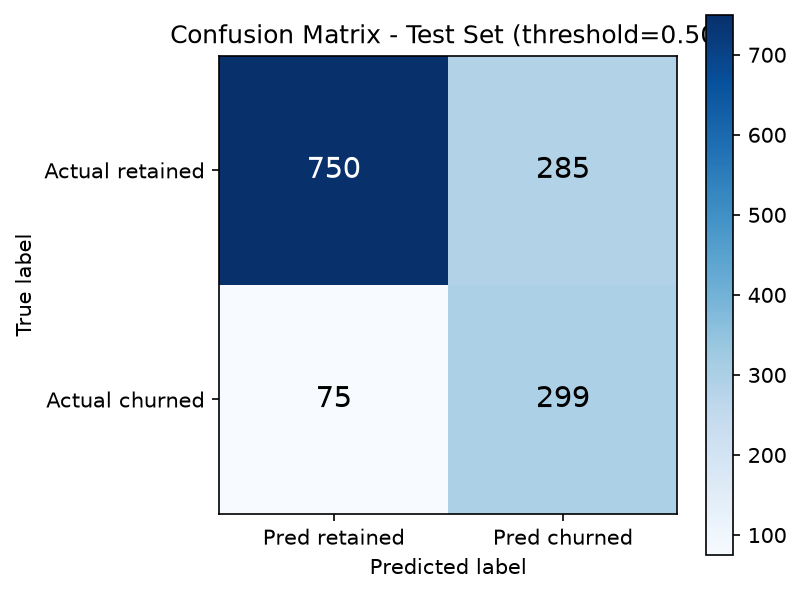

Saved: outputs\figures\10_roc_curve.png


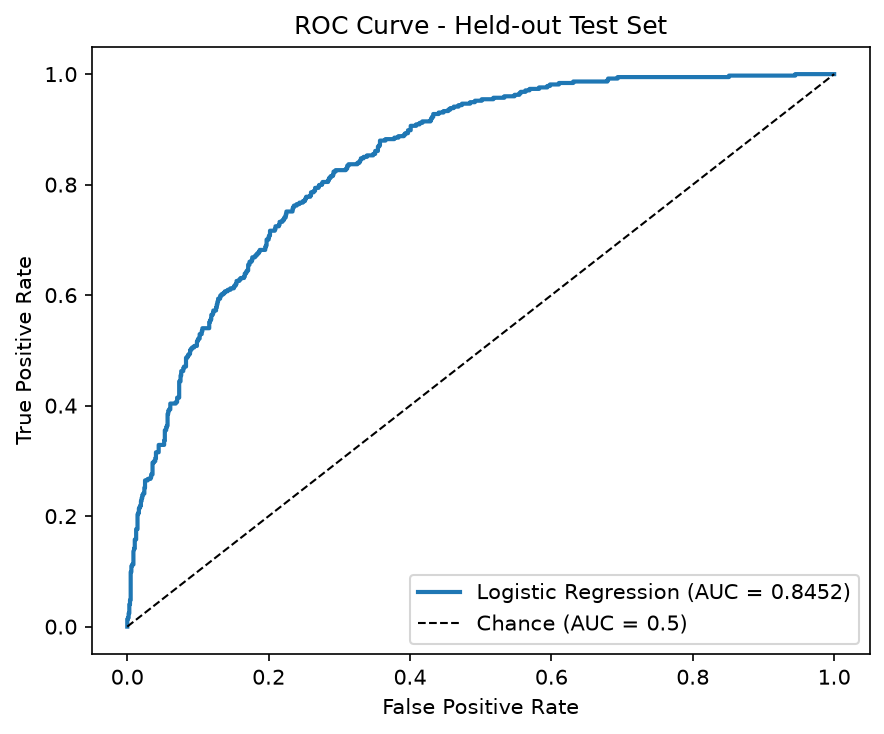

Saved: outputs\figures\11_precision_recall_curve.png


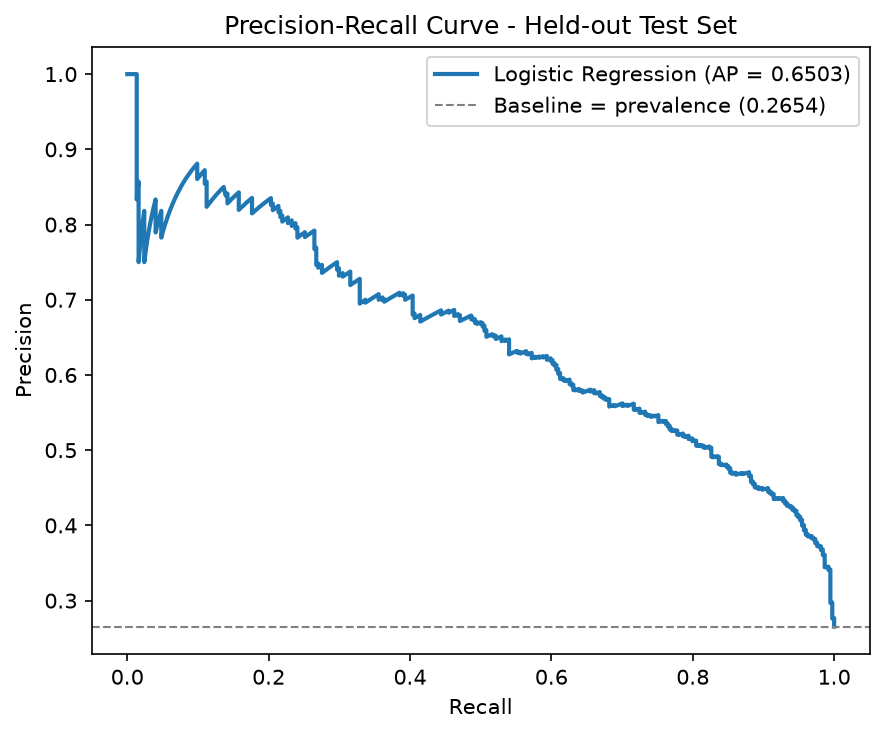

In [11]:
fig_cm = ev.plot_confusion(y_test, primary_test["y_proba"], 0.5, prep.FIGURES_DIR / "09_confusion_matrix.png")
fig_roc = ev.plot_roc(y_test, primary_test["y_proba"], prep.FIGURES_DIR / "10_roc_curve.png")
fig_pr = ev.plot_pr(y_test, primary_test["y_proba"], prep.FIGURES_DIR / "11_precision_recall_curve.png")
for p in [fig_cm, fig_roc, fig_pr]:
    print("Saved:", p)
    display(Image(filename=str(p), width=460))

## 10. Threshold analysis

Raw churn probability (`predict_proba[:,1]`) is kept **separate** from binary predictions.
Business threshold selection is based on **out-of-fold TRAINING probabilities**; the test table
is descriptive reference only.

In [12]:
from sklearn.model_selection import cross_val_predict

oof_proba = cross_val_predict(prep.build_pipeline(class_weight=weight_choice),
                              X_train, y_train, cv=train.CV, method="predict_proba", n_jobs=1)[:, 1]
thr_oof = ev.threshold_table(y_train, oof_proba, train.THRESHOLDS)
thr_test = ev.threshold_table(y_test, primary_test["y_proba"], train.THRESHOLDS)
results["thresholds_oof"], results["thresholds_test"] = thr_oof, thr_test
print("Out-of-fold TRAINING probabilities (business threshold selection basis):")
display(thr_oof)
print("Held-out TEST set (descriptive reference only, not used to select):")
display(thr_test)

Out-of-fold TRAINING probabilities (business threshold selection basis):


,threshold,precision,recall,f1,n_flagged,pct_flagged
0,0.3,0.4301,0.9177,0.5857,3190,56.62
1,0.4,0.4708,0.8676,0.6104,2755,48.90
2,0.5,0.5223,0.7920,0.6295,2267,40.24
3,0.6,0.5750,0.7077,0.6345,1840,32.66
4,0.7,0.6394,0.5906,0.6140,1381,24.51


Held-out TEST set (descriptive reference only, not used to select):


,threshold,precision,recall,f1,n_flagged,pct_flagged
0,0.3,0.4365,0.9278,0.5937,795,56.42
1,0.4,0.4689,0.8663,0.6085,691,49.04
2,0.5,0.5120,0.7995,0.6242,584,41.45
3,0.6,0.5591,0.7086,0.6250,474,33.64
4,0.7,0.6246,0.5829,0.6030,349,24.77


## 11. Feature redundancy (training data only)

Correlation, VIF and per-fold coefficient stability. No feature is deleted on correlation alone -
the ablation (section 12) provides the empirical test.

In [13]:
corr_train = X_train[prep.NUMERIC_FEATURES].corr().round(4)
vif = train.vif_table(X_train, prep.NUMERIC_FEATURES)
stability = train.coefficient_stability(X_train, y_train, weight_choice)
results["corr_train"], results["vif"], results["stability"] = corr_train, vif, stability
print("Correlation matrix (numeric block):")
display(corr_train)
print("\nVIF (numeric block):")
display(vif)
print("\nNumeric coefficients per CV fold (std + sign-consistency rows at bottom):")
display(stability)

Correlation matrix (numeric block):


,tenure,MonthlyCharges,TotalCharges,ServiceCount,HasSecuritySupport,AvgMonthlyCharge
tenure,1.0000,0.2567,0.8297,0.5325,0.3560,0.2557
MonthlyCharges,0.2567,1.0000,0.6541,0.7736,0.4063,0.9963
TotalCharges,0.8297,0.6541,1.0000,0.7861,0.4815,0.6537
ServiceCount,0.5325,0.7736,0.7861,1.0000,0.6572,0.7714
HasSecuritySupport,0.3560,0.4063,0.4815,0.6572,1.0000,0.4060
AvgMonthlyCharge,0.2557,0.9963,0.6537,0.7714,0.4060,1.0000



VIF (numeric block):


,Feature,R2_on_others,VIF
0,MonthlyCharges,0.9926,135.72
1,AvgMonthlyCharge,0.9926,135.58
2,TotalCharges,0.8228,5.64
3,ServiceCount,0.8016,5.04
4,tenure,0.5907,2.44
5,HasSecuritySupport,0.4483,1.81



Numeric coefficients per CV fold (std + sign-consistency rows at bottom):


,num__tenure,num__MonthlyCharges,num__TotalCharges,num__ServiceCount,num__HasSecuritySupport,num__AvgMonthlyCharge
fold,,,,,,
1,-0.3512,0.0620,0.0094,0.2321,-0.1268,0.0020
2,-0.4865,-0.6152,-0.0530,0.4053,-0.2628,0.3070
3,-0.4658,-0.3209,0.0777,0.3843,-0.1443,-0.1545
4,-0.4059,-0.5523,-0.0091,0.2044,-0.0873,0.4994
5,-0.4821,-0.3603,0.0307,0.4003,-0.2127,-0.2411
std,0.0584,0.2654,0.0483,0.0985,0.0703,0.3129
sign_changes,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000


## 12. Feature ablation (5-fold CV on training set)

- **A**: 19 original predictors only
- **B**: all 24 (originals + 5 engineered)
- **C**: originals + ServiceCount + HasSecuritySupport (drops TenureGroup, MonthlyChargeBand,
  AvgMonthlyCharge - justified by the diagnostics above: binned copies; r=0.9963 with
  MonthlyCharges; VIF ~136; unstable fold-signs)

Selection metric: CV ROC-AUC (ranking quality drives customer risk scoring), tie-break F1.

In [14]:
abl = train.ablation_experiment(X_train, y_train, weight_choice)
results["ablation"] = abl
display(abl)
final_choice, final_reason = train.select_final(abl)
results["final_choice"], results["final_reason"] = final_choice, final_reason
print(f"\nFinal feature-set choice: {final_choice}")
print(final_reason)

,Model,n_features,ROC_AUC_Mean,ROC_AUC_Std,F1_Mean,F1_Std,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std
0,A (originals only),19,0.8459,0.0124,0.6296,0.0226,0.5185,0.0181,0.8020,0.0379
1,B (originals + engineered),24,0.8467,0.0115,0.6293,0.0215,0.5223,0.0171,0.7920,0.0339
2,C (originals + ServiceCount + HasSecuritySupport),21,0.8459,0.0131,0.6292,0.0236,0.5193,0.0202,0.7987,0.0377



Final feature-set choice: B (originals + engineered)
Selected by CV ROC-AUC (0.8467; tie-break CV F1 0.6293). ROC-AUC measures how well the model RANKS customers by churn risk, which is the core business need for targeting retention outreach. No test-set information used.


In [15]:
final_num, final_cat = train.ABLATION_SETS[final_choice]
results["class_weight"], results["final_num"], results["final_cat"] = weight_choice, final_num, final_cat
if final_choice == "B (originals + engineered)":
    final_pipeline = primary
    final_test = primary_test
else:
    final_pipeline = prep.build_pipeline(final_num, final_cat, class_weight=weight_choice)
    final_pipeline.fit(X_train, y_train)
    final_test = train.test_evaluation(final_pipeline, X_test, y_test,
                                       f"LogisticRegression ({final_choice}, class_weight={weight_choice})")
    print("Final model test metrics:", {k: final_test["metrics"][k] for k in ev.METRICS})
results["final_test"] = final_test
print("Final model =", final_choice, "| class_weight =", weight_choice)
print("Final test metrics (single pass):", {k: final_test["metrics"][k] for k in ev.METRICS})

Final model = B (originals + engineered) | class_weight = balanced
Final test metrics (single pass): {'accuracy': 0.7445, 'precision': 0.512, 'recall': 0.7995, 'f1': 0.6242, 'roc_auc': 0.8452}


## 13. Coefficient interpretation

Odds ratio = exp(coefficient), holding all other included variables constant.
Associations only - no causal claims. The coefficient count is verified against the
transformed feature count inside `extract_coefficients`.

In [16]:
coefficients = train.extract_coefficients(final_pipeline)
coefficients.to_csv(train.COEF_PATH, index=False)
results["coefficients"] = coefficients
print(f"Saved {train.COEF_PATH} - {len(coefficients)} coefficients == {n_transformed if final_choice == 'B (originals + engineered)' else len(coefficients)} transformed features (asserted)")
display(coefficients.head(20))

Saved outputs\reports\logistic_coefficients.csv - 39 coefficients == 39 transformed features (asserted)


,Feature,Coefficient,OddsRatio,Direction
0,cat__Contract_Two year,-1.608995,0.200089,negative
1,cat__InternetService_Fiber optic,1.299366,3.666971,positive
2,cat__TenureGroup_≤6 months,0.886605,2.426876,positive
3,cat__Contract_One year,-0.724558,0.484538,negative
4,num__MonthlyCharges,-0.501878,0.605392,negative
5,num__tenure,-0.442369,0.642512,negative
6,num__ServiceCount,0.402041,1.494872,positive
7,cat__PaymentMethod_Electronic check,0.391443,1.479114,positive
8,cat__PaperlessBilling_Yes,0.347751,1.415879,positive
9,cat__OnlineBackup_Yes,-0.265770,0.766615,negative


## 14. Save the complete pipeline (preprocessing + classifier) and verify reload

In [17]:
model_path = train.save_model(final_pipeline)
reload_checks = train.verify_saved_model(model_path, X_test, final_test["y_pred"], final_test["y_proba"])
results["model_path"], results["reload_checks"] = model_path, reload_checks
ev.save_test_metrics_csv(
    [
        {"model": "DummyClassifier(prior)", **{k: baseline["test"][k] for k in ["tn", "fp", "fn", "tp", "accuracy", "precision", "recall", "f1", "roc_auc"]}},
        {"model": f"LogisticRegression final ({final_choice}, class_weight={weight_choice})",
         **{k: final_test["metrics"][k] for k in ["tn", "fp", "fn", "tp", "accuracy", "precision", "recall", "f1", "roc_auc"]}},
    ],
    prep.REPORT_DIR / "test_metrics.csv",
)
print("Saved model :", model_path)
print("Reload check:", reload_checks)
print("Saved       :", prep.REPORT_DIR / "test_metrics.csv")

Saved model : models\churn_model.pkl
Reload check: {'predictions identical': True, 'probabilities identical': True, 'pipeline contains preprocessing': True, 'pipeline contains classifier': True}
Saved       : outputs\reports\test_metrics.csv


## 15. Final conclusions + report generation

In [18]:
results["clean_sha"], results["raw_sha"] = clean_sha_before, raw_sha
train.write_report(results)
print("Report written:", train.REPORT_PATH, "exists =", train.REPORT_PATH.exists())

assert prep.clean_sha256() == clean_sha_before, "Cleaned dataset was modified!"
print("PASS: data/processed/cleaned_customer_churn.csv byte-for-byte unchanged.")

fm = final_test["metrics"]
print(f"""
FINAL CONCLUSIONS (actual results)
----------------------------------
- Baseline (prior): accuracy {baseline['test']['accuracy']:.4f}, ROC-AUC {baseline['test']['roc_auc']:.4f}, F1 {baseline['test']['f1']:.4f}.
- Logistic Regression CV (training): accuracy {train.cv_value(primary_cv, 'accuracy'):.4f}, F1 {train.cv_value(primary_cv, 'f1'):.4f}, ROC-AUC {train.cv_value(primary_cv, 'roc_auc'):.4f}.
- Held-out test: accuracy {fm['accuracy']:.4f}, precision {fm['precision']:.4f}, recall {fm['recall']:.4f}, F1 {fm['f1']:.4f}, ROC-AUC {fm['roc_auc']:.4f}
  (TN={fm['tn']}, FP={fm['fp']}, FN={fm['fn']}, TP={fm['tp']}).
- Final configuration: {final_choice}, class_weight={weight_choice}, C=1.0, lbfgs, 39 transformed features.
- Strongest churn-increasing associations: Fiber optic internet, <=6 months tenure,
  electronic check, paperless billing; churn-decreasing: two-year contract, one-year contract,
  OnlineSecurity/OnlineBackup subscription. Associations only, not causal effects.
- The model materially beats the no-skill floor and is suitable for customer risk SCORING;
  the business threshold should be chosen from OOF training predictions (section 10).
""")
print("PHASE 6 MODEL TRAINING: SUCCESS")

Report written: outputs\reports\model_training_report.txt exists = True
PASS: data/processed/cleaned_customer_churn.csv byte-for-byte unchanged.

FINAL CONCLUSIONS (actual results)
----------------------------------
- Baseline (prior): accuracy 0.7346, ROC-AUC 0.5000, F1 0.0000.
- Logistic Regression CV (training): accuracy 0.7526, F1 0.6293, ROC-AUC 0.8467.
- Held-out test: accuracy 0.7445, precision 0.5120, recall 0.7995, F1 0.6242, ROC-AUC 0.8452
  (TN=750, FP=285, FN=75, TP=299).
- Final configuration: B (originals + engineered), class_weight=balanced, C=1.0, lbfgs, 39 transformed features.
- Strongest churn-increasing associations: Fiber optic internet, <=6 months tenure,
  electronic check, paperless billing; churn-decreasing: two-year contract, one-year contract,
  OnlineSecurity/OnlineBackup subscription. Associations only, not causal effects.
- The model materially beats the no-skill floor and is suitable for customer risk SCORING;
  the business threshold should be chosen fro